In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch version:", torch.__version__)

Device: cpu
PyTorch version: 2.14.1+cpu


In [2]:
X_train = np.load("../data/processed/elia_X_train.npy")
X_val   = np.load("../data/processed/elia_X_val.npy")
X_test  = np.load("../data/processed/elia_X_test.npy")

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

X_train: (33700, 24)
X_val:   (7221, 24)
X_test:  (7222, 24)


In [3]:
X_train_3d = X_train.reshape(-1, 24, 1).astype(np.float32)
X_val_3d   = X_val.reshape(-1, 24, 1).astype(np.float32)
X_test_3d  = X_test.reshape(-1, 24, 1).astype(np.float32)

print("3D shapes:", X_train_3d.shape, X_val_3d.shape, X_test_3d.shape)

3D shapes: (33700, 24, 1) (7221, 24, 1) (7222, 24, 1)


In [4]:
class LSTMAutoencoder(nn.Module):
    def __init__(self, input_size=1, hidden=32, latent=8):
        super().__init__()
        self.encoder_lstm = nn.LSTM(input_size, hidden, batch_first=True)
        self.encoder_fc   = nn.Linear(hidden, latent)
        self.decoder_fc   = nn.Linear(latent, hidden)
        self.decoder_lstm = nn.LSTM(hidden, input_size, batch_first=True)

    def forward(self, x):
        _, (h, _) = self.encoder_lstm(x)
        h = h.squeeze(0)
        z = self.encoder_fc(h)
        h_dec = self.decoder_fc(z).unsqueeze(1).repeat(1, 24, 1)
        out, _ = self.decoder_lstm(h_dec)
        return out, z

model = LSTMAutoencoder(input_size=1, hidden=32, latent=8).to(device)
print(model)
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

LSTMAutoencoder(
  (encoder_lstm): LSTM(1, 32, batch_first=True)
  (encoder_fc): Linear(in_features=32, out_features=8, bias=True)
  (decoder_fc): Linear(in_features=8, out_features=32, bias=True)
  (decoder_lstm): LSTM(32, 1, batch_first=True)
)
Total parameters: 5,172


In [5]:
batch_size = 256

train_ds = TensorDataset(torch.tensor(X_train_3d))
val_ds   = TensorDataset(torch.tensor(X_val_3d))

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

Train batches: 132, Val batches: 29


In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

t0 = time.time()
batch = next(iter(train_loader))[0].to(device)
optimizer.zero_grad()
recon, _ = model(batch)
loss = criterion(recon, batch)
loss.backward()
optimizer.step()
step_time = time.time() - t0

print(f"One training step: {step_time:.3f}s")
print(f"Estimated epoch: {step_time * len(train_loader):.1f}s")
print(f"Estimated 20 epochs: {step_time * len(train_loader) * 20 / 60:.1f} min")

One training step: 0.244s
Estimated epoch: 32.2s
Estimated 20 epochs: 10.7 min


In [7]:
EPOCHS = 20
LR = 1e-3

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
criterion = nn.MSELoss()

train_losses, val_losses = [], []

for epoch in range(EPOCHS):
    t0 = time.time()

    # --- Train ---
    model.train()
    running = 0.0
    for (batch,) in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        recon, _ = model(batch)
        loss = criterion(recon, batch)
        loss.backward()
        optimizer.step()
        running += loss.item() * batch.size(0)
    train_loss = running / len(train_ds)

    # --- Validate ---
    model.eval()
    running = 0.0
    with torch.no_grad():
        for (batch,) in val_loader:
            batch = batch.to(device)
            recon, _ = model(batch)
            running += criterion(recon, batch).item() * batch.size(0)
    val_loss = running / len(val_ds)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1:2d}/{EPOCHS} | train {train_loss:.6f} | val {val_loss:.6f} | {time.time()-t0:.1f}s")

Epoch  1/20 | train 0.052388 | val 0.030096 | 8.6s
Epoch  2/20 | train 0.017582 | val 0.017086 | 9.3s
Epoch  3/20 | train 0.015559 | val 0.016958 | 8.9s
Epoch  4/20 | train 0.015503 | val 0.016920 | 9.2s
Epoch  5/20 | train 0.015484 | val 0.016916 | 9.1s
Epoch  6/20 | train 0.015482 | val 0.016929 | 8.8s
Epoch  7/20 | train 0.015474 | val 0.016909 | 8.7s
Epoch  8/20 | train 0.015470 | val 0.016927 | 9.0s
Epoch  9/20 | train 0.015468 | val 0.016911 | 9.7s
Epoch 10/20 | train 0.015476 | val 0.016900 | 9.4s
Epoch 11/20 | train 0.015461 | val 0.016896 | 8.3s
Epoch 12/20 | train 0.015463 | val 0.016894 | 10.5s
Epoch 13/20 | train 0.015460 | val 0.016901 | 9.3s
Epoch 14/20 | train 0.015460 | val 0.016899 | 9.4s
Epoch 15/20 | train 0.015461 | val 0.016903 | 9.9s
Epoch 16/20 | train 0.015457 | val 0.016886 | 9.7s
Epoch 17/20 | train 0.015453 | val 0.016941 | 8.9s
Epoch 18/20 | train 0.015440 | val 0.016843 | 9.5s
Epoch 19/20 | train 0.015385 | val 0.016975 | 9.3s
Epoch 20/20 | train 0.015459 |

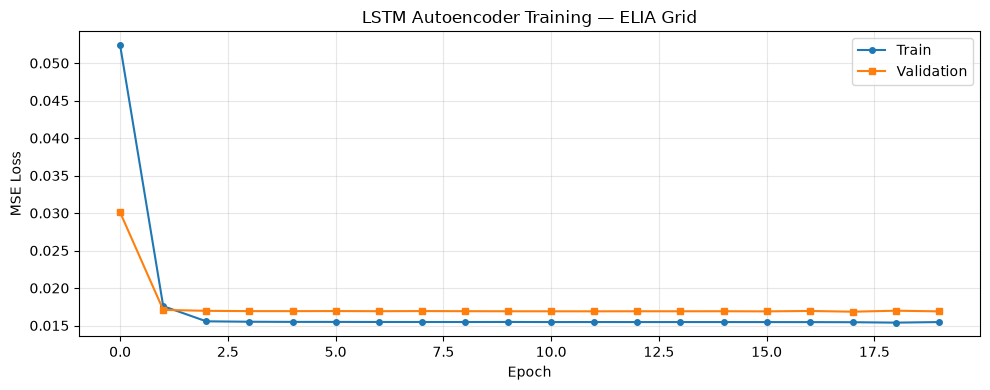

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(train_losses, label="Train", marker="o", markersize=4)
plt.plot(val_losses,   label="Validation", marker="s", markersize=4)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Autoencoder Training — ELIA Grid")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../data/processed/autoencoder_loss.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
def extract_features(X_3d, model, batch_size=512):
    model.eval()
    feats = []
    with torch.no_grad():
        for i in range(0, len(X_3d), batch_size):
            batch = torch.tensor(X_3d[i:i+batch_size]).to(device)
            _, z = model(batch)
            feats.append(z.cpu().numpy())
    return np.vstack(feats)

F_train = extract_features(X_train_3d, model)
F_val   = extract_features(X_val_3d,   model)
F_test  = extract_features(X_test_3d,  model)

print("F_train:", F_train.shape)
print("F_val:  ", F_val.shape)
print("F_test: ", F_test.shape)

F_train: (33700, 8)
F_val:   (7221, 8)
F_test:  (7222, 8)


In [10]:
np.save("../data/processed/elia_F_train.npy", F_train)
np.save("../data/processed/elia_F_val.npy",   F_val)
np.save("../data/processed/elia_F_test.npy",  F_test)

torch.save(model.state_dict(), "../models/lstm_autoencoder.pt")
print("Saved features and model.")

Saved features and model.
